# Interpretabilidad de los Modelos Finales

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

pd.set_option("display.max_colwidth", None)

from Interpretabilidad import (
    SEED, NOMBRE_SEXO,
    cargar_modelos, verificar_modelos, preparar_datos, extraer_componentes, nombres_legibles, transformar, valores_originales,
    tabla_coeficientes, graficar_coeficientes,
    importancia_catboost, graficar_importancia_catboost,
    shap_catboost, shap_lineal, verificar_aditividad, salida_logodds_catboost, importancia_shap,
    graficar_shap_barras, graficar_shap_beeswarm, graficar_dependencias, graficar_waterfall,
    elegir_casos_clasificacion, elegir_casos_regresion,
    crear_explicador_lime, explicar_lime, graficar_lime, comparar_lime_shap,
    importancia_permutacion, graficar_permutacion,
    tabla_importancias, guardar_resultados,
)

/opt/conda/envs/screen-time-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Carga de los Modelos

In [2]:
modelos = cargar_modelos()
clasificador, metadatos_clf = modelos["clasificador"], modelos["metadatos_clf"]
regresor, metadatos_reg = modelos["regresor"], modelos["metadatos_reg"]
UMBRAL = metadatos_clf["umbral"]

verificar_modelos(modelos)

,Modelo (metadatos),Estimador final,Variante,Umbral,Hiperparámetros,Correcto
Problema,,,,,,
Clasificación (depressed),CatBoost,CatBoostClassifier,estrategia nativo,0.15342,"{'depth': 4, 'iterations': 232, 'l2_leaf_reg': 1.5720251525742128, 'learning_rate': 0.02538617845650057}",True
Regresión (bdi_total),ElasticNet,ElasticNet,target nativo,NaN,"{'alpha': 0.01444525102276306, 'l1_ratio': 0.3329833121584336}",True


### Datos: Split y Test

El test se reconstruye desde `split_indices.csv`, el mismo de todo el modelado, y todas las explicaciones se calculan sobre él. El train solo se usa como referencia: datos de fondo de SHAP en el ElasticNet y distribución de referencia de LIME.

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

datos = preparar_datos(df)
X_train, X_test = datos["X_train"], datos["X_test"]
y_dep_test, y_bdi_test, subject_id_test = datos["y_dep_test"], datos["y_bdi_test"], datos["subject_id_test"]

pd.DataFrame({
    "Filas": [len(X_train), len(X_test)],
    "Deprimidos": [None, int(y_dep_test.sum())],
    "BDI medio": [None, round(y_bdi_test.mean(), 2)],
}, index=pd.Index(["Train (referencia)", "Test"], name="Conjunto"))

,Filas,Deprimidos,BDI medio
Conjunto,,,
Train (referencia),3848,NaN,NaN
Test,962,157.0,7.15


### Componentes de los Pipelines

De cada pipeline se extraen el preprocesador ajustado (`StandardScaler` + `OneHotEncoder(drop="first")`), el estimador final y los nombres de las variables transformadas (`get_feature_names_out`). Los dos modelos comparten el mismo preprocesamiento, así que ven las mismas 6 columnas en el mismo orden. Para las gráficas se usan los nombres legibles y los valores originales de cada variable (sin estandarizar); `sex` se representa como 0 = chico y 1 = chica.

In [4]:
prep_clf, catboost, nombres_clf = extraer_componentes(clasificador)
prep_reg, elasticnet, nombres_reg = extraer_componentes(regresor)
assert nombres_clf == nombres_reg, "Los dos pipelines deberían producir las mismas columnas"

nombres = nombres_legibles(nombres_clf)

# Test preprocesado con el preprocesador de cada modelo y valores originales para las gráficas
X_test_clf = transformar(prep_clf, X_test)
X_test_reg = transformar(prep_reg, X_test)
X_train_reg = transformar(prep_reg, X_train)
originales_test = valores_originales(X_test, nombres_clf)

pd.DataFrame({"Variable transformada": nombres_clf, "Nombre legible": nombres})

,Variable transformada,Nombre legible
0,numericas__sleep_quality_index,Índice de calidad del sueño
1,numericas__avg_sleep_hours,Horas de sueño promedio
2,numericas__midsleep_weekend_hours,Punto medio del sueño (fin de semana)
3,numericas__social_jetlag_hours,Jet lag social
4,numericas__screen_time_index,Índice de tiempo de pantalla
5,categoricas__sex_Girl,Sexo (chica)


## 1. Interpretación de los Coeficientes (ElasticNet)

Las variables numéricas están estandarizadas, así que cada coeficiente es el **cambio en puntos BDI por cada desviación estándar** del predictor, con las demás variables fijas. Para `sex`, es la diferencia de las chicas frente a los chicos. La columna `Efecto por unidad original` divide el coeficiente por la desviación estándar del train (la del `StandardScaler` ajustado) para leerlo en la unidad de cada variable, por ejemplo, "por cada hora más de sueño". La columna `En cero (L1)` marca los coeficientes que la penalización L1 anuló.

In [5]:
coeficientes = tabla_coeficientes(prep_reg, elasticnet, nombres_reg)
coeficientes.round(3)

,Coeficiente (por DE),DE del train,Efecto por unidad original,Unidad,En cero (L1)
Variable,,,,,
Sexo (chica),3.039,NaN,3.039,chica frente a chico,False
Índice de calidad del sueño,2.199,0.852,2.581,punto del índice,False
Horas de sueño promedio,-0.905,1.264,-0.716,hora,False
Índice de tiempo de pantalla,0.444,1.024,0.434,punto del índice,False
Punto medio del sueño (fin de semana),0.408,1.401,0.291,hora,False
Jet lag social,-0.000,1.133,-0.000,hora,True


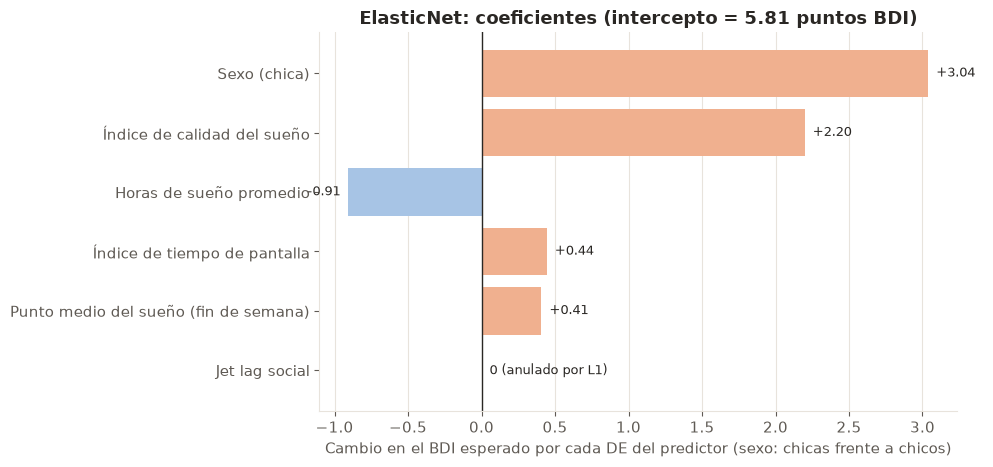

In [6]:
fig = graficar_coeficientes(coeficientes, elasticnet.intercept_)
plt.show()

## 2. Importancia Nativa (CatBoost)

CatBoost calcula dos importancias propias:

- **`PredictionValuesChange`:** cuánto cambia, en promedio, la predicción cuando cambia el valor de la variable (normalizada para que sume 100). Se calcula con la estructura de los árboles, sin datos.
- **`LossFunctionChange`:** cuánto empeora la pérdida (Logloss) al quitar la variable del modelo. Se calcula con un `Pool` del test ya preprocesado, así que mide la contribución de cada variable al desempeño en datos no vistos.

In [7]:
importancia_nativa = importancia_catboost(catboost, X_test_clf, y_dep_test, nombres)
importancia_nativa.round(3)

,PredictionValuesChange,LossFunctionChange
Variable,,
Índice de calidad del sueño,30.606,0.039
Sexo (chica),26.968,0.015
Horas de sueño promedio,14.257,0.004
Punto medio del sueño (fin de semana),10.838,0.002
Jet lag social,9.573,0.002
Índice de tiempo de pantalla,7.758,0.001


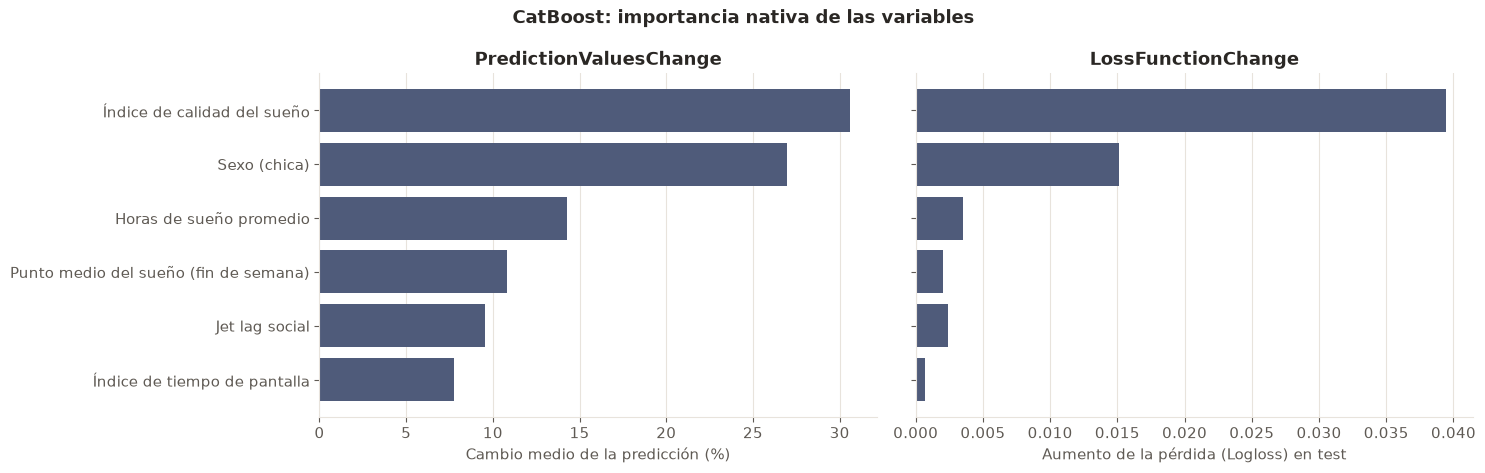

In [8]:
fig = graficar_importancia_catboost(importancia_nativa)
plt.show()

**Limitaciones de la importancia nativa:**

- **No indica la dirección del efecto:** dice cuánto pesa una variable, pero no si aumenta o reduce el riesgo.
- **Favorece a las variables continuas con muchos valores distintos**, porque ofrecen más puntos de corte a los árboles. Puede subestimar a `sex`, que es binaria y solo admite una división.
- **Reparte la importancia entre variables correlacionadas.** `midsleep_weekend_hours` y `social_jetlag_hours` (r = 0.84) contienen información parecida, y el modelo puede usar una u otra de forma intercambiable, así que la importancia de cada una por separado subestima la del dominio que comparten.

## 3. SHAP

Los valores SHAP reparten la predicción de cada adolescente entre las variables: para cada observación, **la base (la predicción media) más la suma de sus valores SHAP es igual a la predicción del modelo**. Un valor positivo indica que esa variable empuja la predicción hacia arriba en ese adolescente, y uno negativo, hacia abajo. A diferencia de la importancia nativa, SHAP da la dirección del efecto y explica cada predicción individual.

Los `shap.Explanation` se construyen con los valores originales de las variables (sin estandarizar) y nombres legibles, así que los ejes y los colores se leen en las unidades de cada variable.

### CatBoost

`shap.TreeExplainer` calcula los valores SHAP exactos del ensamble sobre el test preprocesado. Están en **escala log-odds**: la base es el log-odds medio de depresión, y la suma de los SHAP de un adolescente da su log-odds, que se convierte en probabilidad con la función logística. Un SHAP de +0.5 multiplica las odds por e^0.5 ≈ 1.65. La comprobación de aditividad confirma que la base más la suma de los SHAP reproduce la salida del modelo.

In [9]:
shap_clf = shap_catboost(catboost, X_test_clf, originales_test)

print(f"Base (log-odds medio): {shap_clf.base_values[0]:.3f}")
print(f"Aditividad, máxima diferencia con la salida del modelo: {verificar_aditividad(shap_clf, salida_logodds_catboost(catboost, X_test_clf)):.2e}")
importancia_shap(shap_clf).round(4).to_frame()

Base (log-odds medio): -1.925
Aditividad, máxima diferencia con la salida del modelo: 4.88e-15


,Media de |SHAP|
Sexo (chica),0.5446
Índice de calidad del sueño,0.4104
Horas de sueño promedio,0.1915
Punto medio del sueño (fin de semana),0.1049
Índice de tiempo de pantalla,0.0881
Jet lag social,0.0525


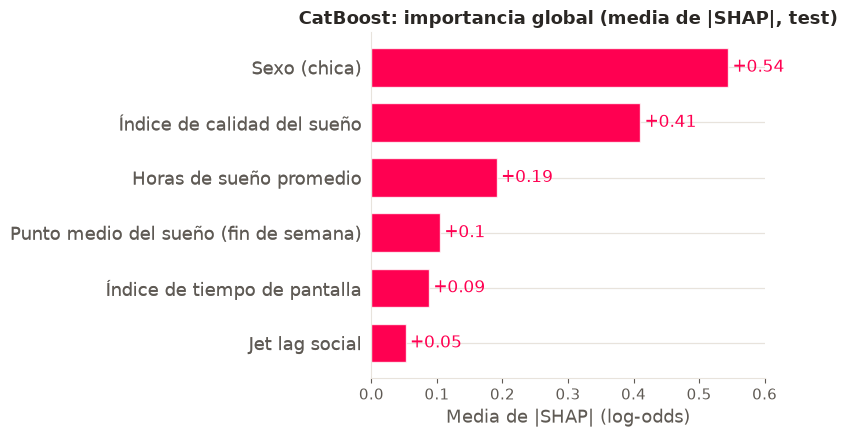

In [10]:
fig = graficar_shap_barras(shap_clf, "CatBoost: importancia global (media de |SHAP|, test)", "log-odds")
plt.show()

En el beeswarm, cada punto es un adolescente del test. La posición horizontal es su valor SHAP y el color, el valor original de la variable (rojo = alto, azul = bajo). Si los puntos rojos quedan a la derecha, valores altos de la variable aumentan el riesgo.

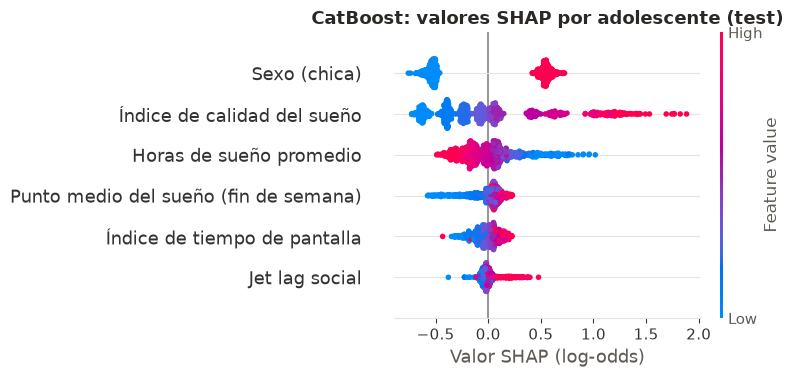

In [11]:
fig = graficar_shap_beeswarm(shap_clf, "CatBoost: valores SHAP por adolescente (test)", "log-odds")
plt.show()

**Dependence plots.** Para las 3 variables más importantes según SHAP, el valor original de la variable (eje x) frente a su valor SHAP (eje y), coloreados por sexo. Muestran la forma del efecto (lineal, con umbrales o saturación) y si difiere entre chicos y chicas, que es lo que un árbol puede capturar y un modelo lineal no.

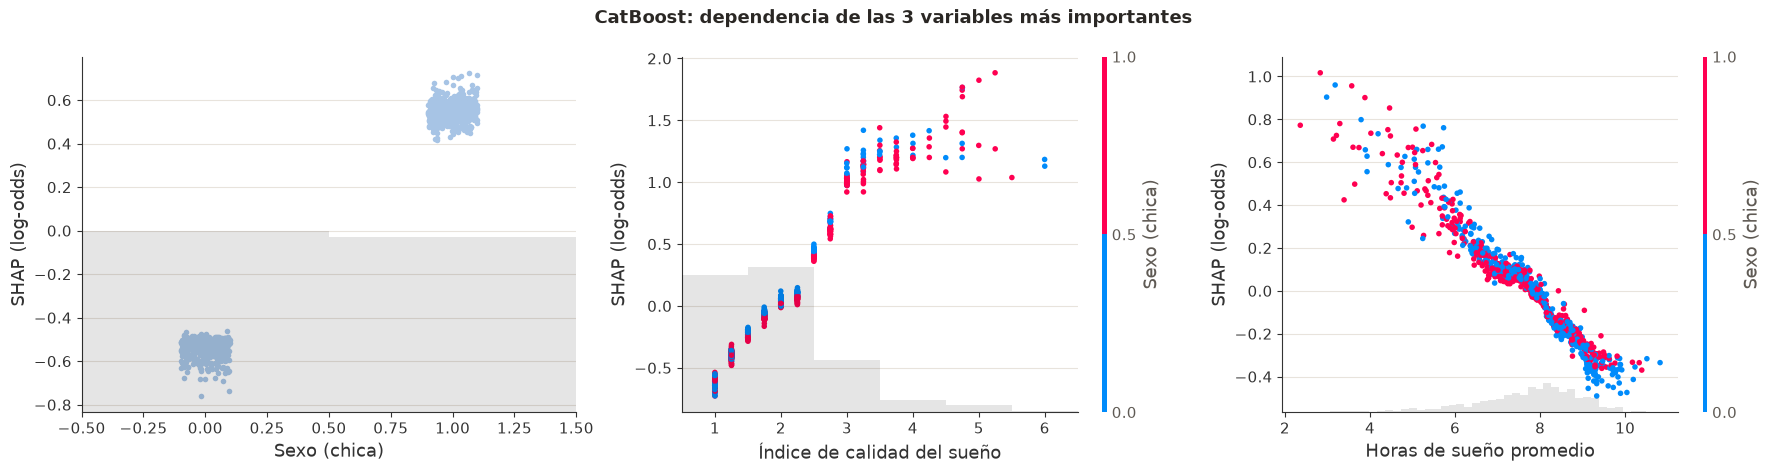

In [12]:
top_clf = list(importancia_shap(shap_clf).index[:3])
fig = graficar_dependencias(shap_clf, top_clf, "CatBoost: dependencia de las 3 variables más importantes", "log-odds")
plt.show()

**Explicaciones individuales.** Se eligen 3 adolescentes del test de forma reproducible (`SEED` = 42), según la clasificación con el umbral de tamizaje del modelo final: un verdadero positivo, un falso negativo y un falso positivo. El waterfall muestra cómo cada variable lleva el log-odds desde la base hasta el valor de ese adolescente.

In [13]:
proba_test = clasificador.predict_proba(X_test)[:, 1]
casos_clf = elegir_casos_clasificacion(y_dep_test, proba_test, UMBRAL, subject_id_test, seed=SEED)
casos_clf

,posicion,subject_id,Real,Predicción,Motivo
Caso,,,,,
Verdadero positivo,104,544,1,0.613,verdadero positivo: deprimido y probabilidad ≥ 0.153 (elegido al azar con SEED = 42)
Falso negativo,807,4139,1,0.137,falso negativo: deprimido pero probabilidad < 0.153 (elegido al azar con SEED = 42)
Falso positivo,613,3169,0,0.222,falso positivo: no deprimido pero probabilidad ≥ 0.153 (elegido al azar con SEED = 42)


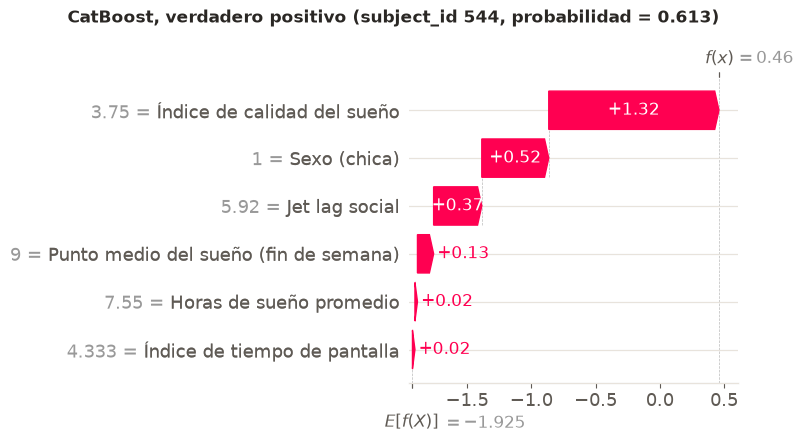

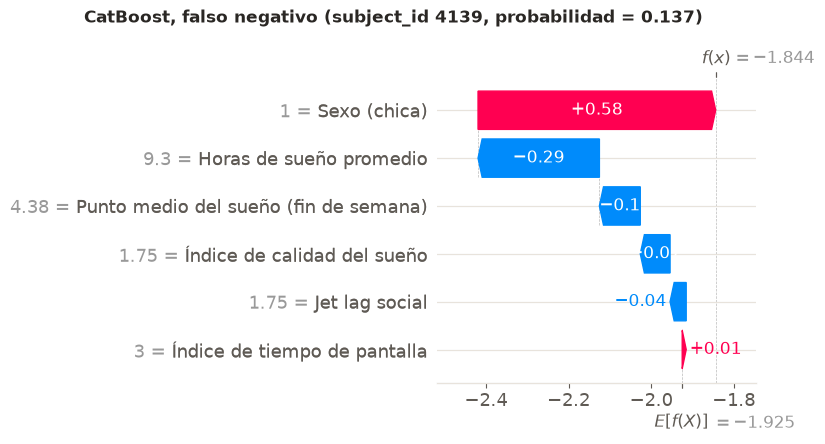

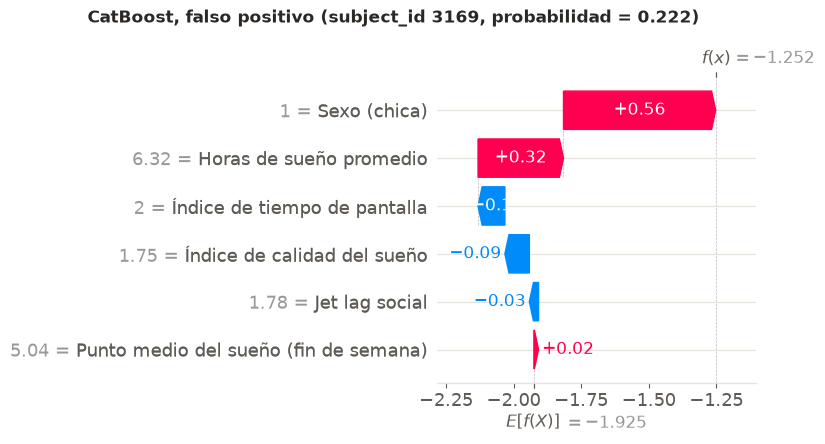

In [14]:
for caso, fila in casos_clf.iterrows():
    fig = graficar_waterfall(shap_clf, fila["posicion"], f"CatBoost, {caso.lower()} (subject_id {fila['subject_id']}, probabilidad = {fila['Predicción']:.3f})")
    plt.show()

### ElasticNet

`shap.LinearExplainer` usa el train preprocesado como datos de fondo, así que la base es la predicción media del train y los valores SHAP están en **puntos BDI**. En un modelo lineal, el SHAP de una variable es simplemente el coeficiente por la desviación del valor respecto a su media: $\phi_j = \beta_j (x_j - \bar x_j)$. Por eso su ranking global es casi el mismo que el de los coeficientes de la sección 1 (multiplicados por la dispersión de cada variable) y el beeswarm muestra, para cada variable, una recta. SHAP explica la salida lineal del ElasticNet, antes del recorte de las predicciones a [0, 63].

In [15]:
shap_reg = shap_lineal(elasticnet, X_train_reg, X_test_reg, originales_test)

print(f"Base (BDI medio predicho en el train): {shap_reg.base_values[0]:.3f}")
print(f"Aditividad, máxima diferencia con la salida del ElasticNet: {verificar_aditividad(shap_reg, elasticnet.predict(X_test_reg)):.2e}")
importancia_shap(shap_reg).round(4).to_frame()

Base (BDI medio predicho en el train): 7.496
Aditividad, máxima diferencia con la salida del ElasticNet: 3.55e-15


,Media de |SHAP|
Índice de calidad del sueño,1.6754
Sexo (chica),1.5226
Horas de sueño promedio,0.7083
Índice de tiempo de pantalla,0.3737
Punto medio del sueño (fin de semana),0.3451
Jet lag social,0.0000


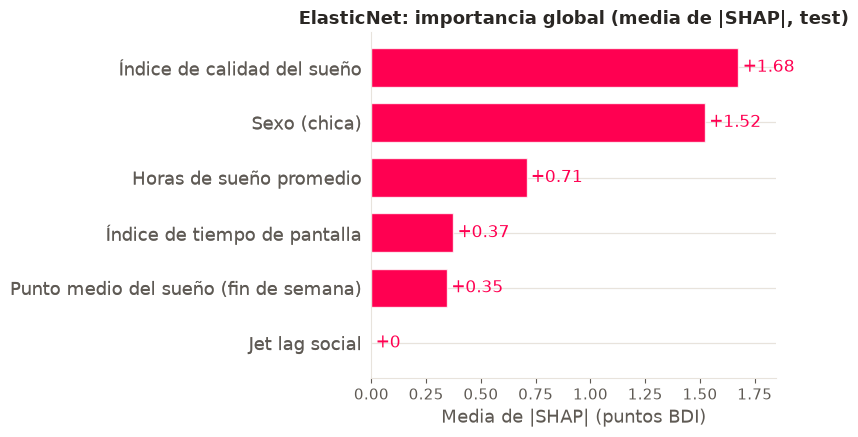

In [16]:
fig = graficar_shap_barras(shap_reg, "ElasticNet: importancia global (media de |SHAP|, test)", "puntos BDI")
plt.show()

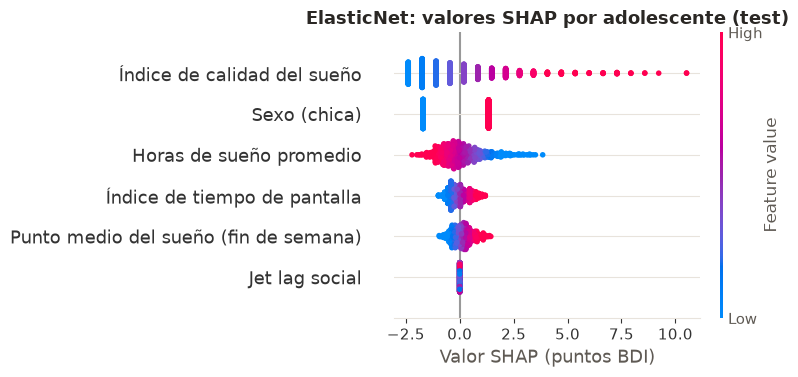

In [17]:
fig = graficar_shap_beeswarm(shap_reg, "ElasticNet: valores SHAP por adolescente (test)", "puntos BDI")
plt.show()

**Explicaciones individuales.** Se eligen 3 adolescentes del test de forma reproducible (`SEED` = 42) según su BDI real: uno bajo (≤ 2), uno cercano al corte clínico (13 a 15) y uno alto (≥ percentil 95 del test).

In [18]:
bdi_predicho = regresor.predict(X_test)
casos_reg = elegir_casos_regresion(y_bdi_test, bdi_predicho, subject_id_test, seed=SEED)
casos_reg

,posicion,subject_id,Real,Predicción,Motivo
Caso,,,,,
BDI bajo,92,473,2,11.73,BDI real ≤ 2 (elegido al azar con SEED = 42)
BDI cercano a 14,797,4092,13,3.32,BDI real entre 13 y 15 (cerca del corte clínico) (elegido al azar con SEED = 42)
BDI alto,661,3403,22,16.09,BDI real ≥ 22 (percentil 95 del test) (elegido al azar con SEED = 42)


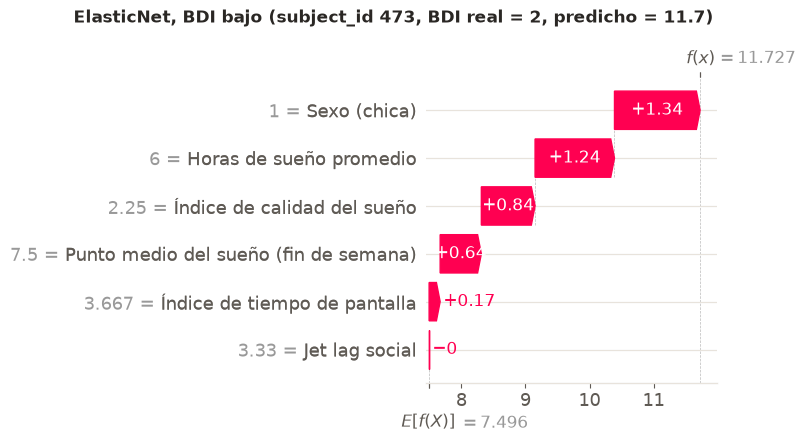

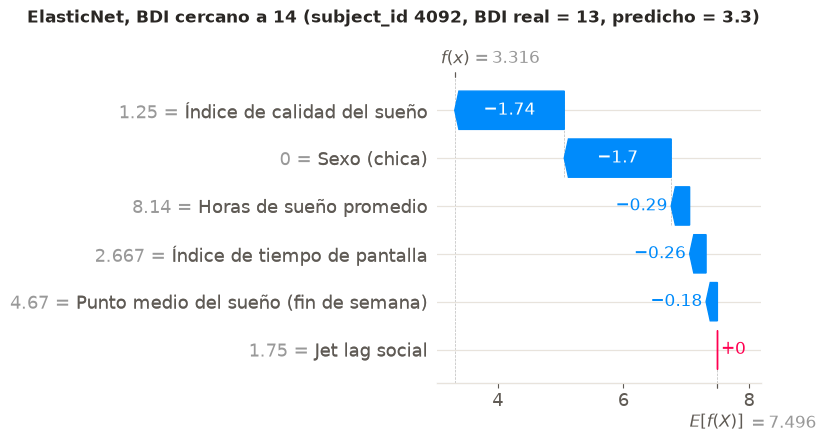

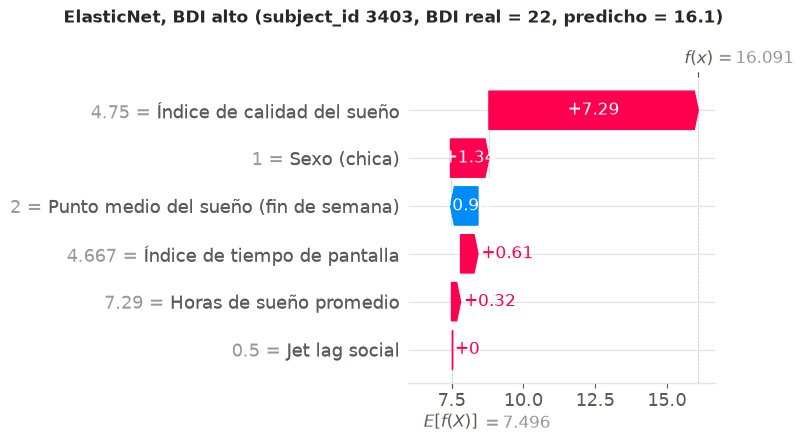

In [19]:
for caso, fila in casos_reg.iterrows():
    fig = graficar_waterfall(shap_reg, fila["posicion"], f"ElasticNet, {caso} (subject_id {fila['subject_id']}, BDI real = {fila['Real']}, predicho = {fila['Predicción']:.1f})")
    plt.show()

## 4. LIME

LIME explica una predicción individual ajustando un **modelo lineal simple alrededor de ese adolescente**: genera muchas observaciones perturbadas cerca de él, obtiene la predicción del modelo para cada una y ajusta una regresión ponderada por cercanía. Los pesos de esa regresión son la explicación local.

- Trabaja sobre las **variables originales**, con el train sin preprocesar como referencia. Las numéricas se discretizan en cuartiles, por eso cada barra es una regla (por ejemplo, "Índice de calidad del sueño > 2.75"), y `sex` se trata como categórica.
- La función de predicción convierte el array de LIME en un DataFrame con las columnas y tipos originales (`sex` de vuelta a "Boy"/"Girl") y llama al **pipeline completo guardado**, con el mismo preprocesamiento que en el modelado.
- Se explican los **mismos 3 adolescentes** de la sección 3, con `num_samples=5000` y `random_state=42`. En CatBoost se explica la probabilidad de la clase "Deprimido" (`predict_proba`) y en ElasticNet, el BDI predicho (`predict`).

### CatBoost

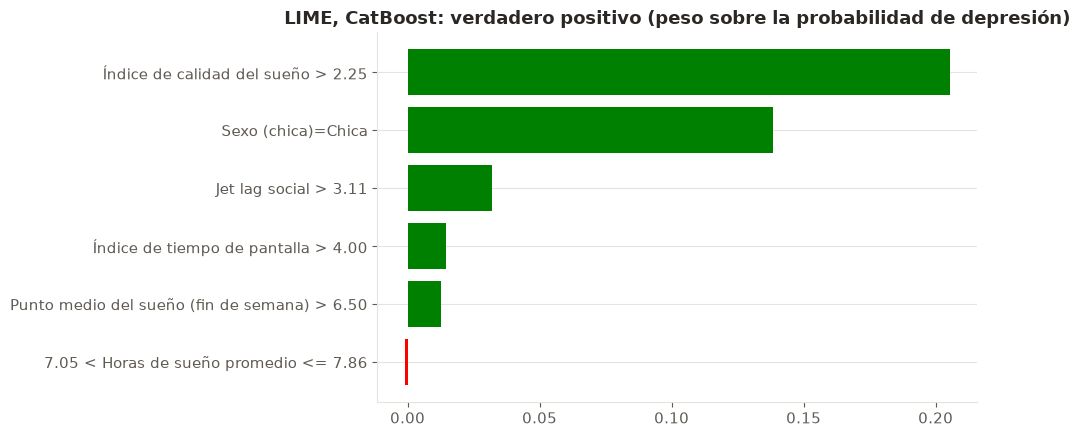

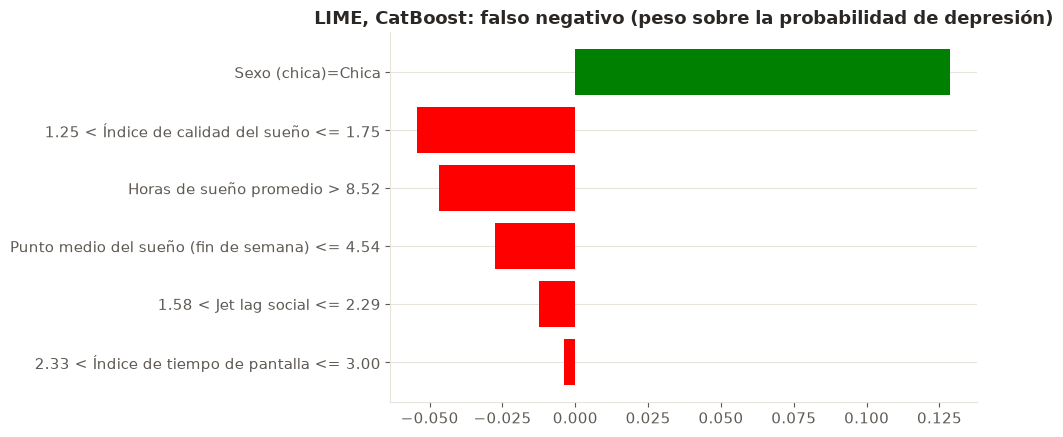

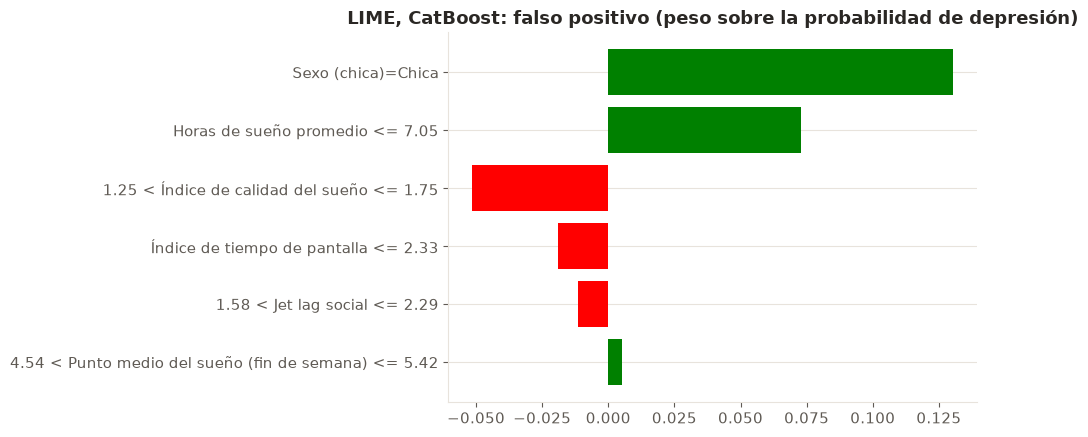

In [20]:
explicador_clf = crear_explicador_lime(X_train, "classification", seed=SEED)
lime_clf = explicar_lime(explicador_clf, clasificador, "classification", X_test, casos_clf, num_samples=5000)

for caso, explicacion in lime_clf.items():
    fig = graficar_lime(explicacion, f"LIME, CatBoost: {caso.lower()} (peso sobre la probabilidad de depresión)")
    plt.show()

### ElasticNet

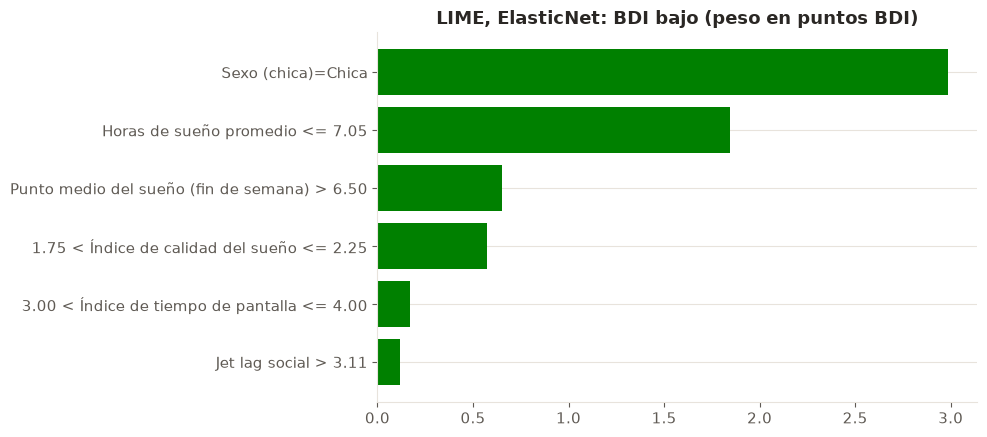

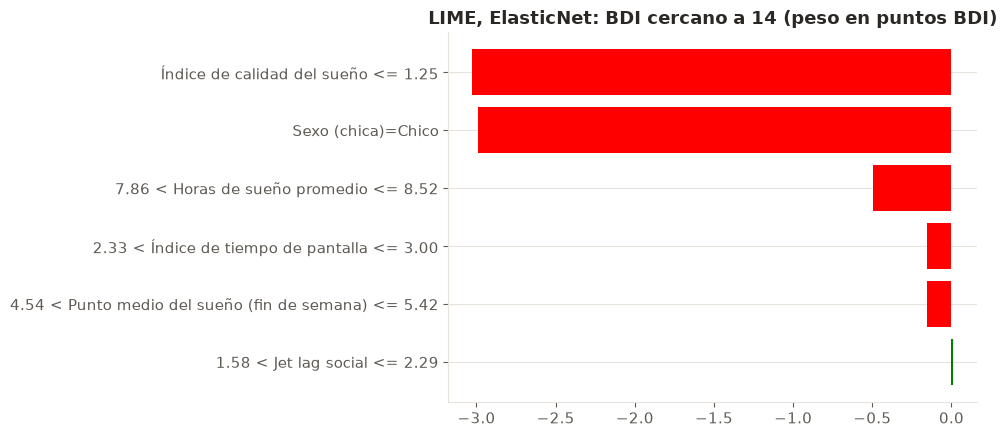

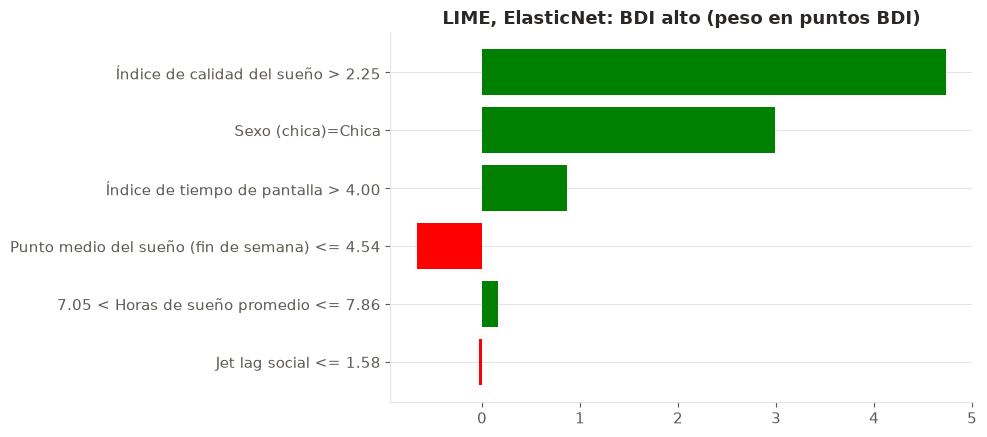

In [21]:
explicador_reg = crear_explicador_lime(X_train, "regression", seed=SEED)
lime_reg = explicar_lime(explicador_reg, regresor, "regression", X_test, casos_reg, num_samples=5000)

for caso, explicacion in lime_reg.items():
    fig = graficar_lime(explicacion, f"LIME, ElasticNet: {caso} (peso en puntos BDI)")
    plt.show()

### LIME frente a SHAP

Para cada adolescente, las 3 variables con mayor peso en valor absoluto según LIME y según SHAP. Las escalas no son comparables: en CatBoost, LIME está en probabilidad y SHAP en log-odds; en ElasticNet, ambos están en puntos BDI, pero LIME mide el efecto de una regla (por ejemplo, estar en el cuartil superior) y SHAP, el de la desviación respecto a la media. Lo que se compara es el **orden** y el **signo**.

In [22]:
comparar_lime_shap(casos_clf, lime_clf, shap_clf, top=3).round(4)

LIME: variable  LIME: peso  \
Caso               Puesto                                            
Verdadero positivo 1       Índice de calidad del sueño      0.2053   
                   2                Sexo (chica)=Chica      0.1383   
                   3                    Jet lag social      0.0320   
Falso negativo     1                Sexo (chica)=Chica      0.1287   
                   2       Índice de calidad del sueño     -0.0543   
                   3           Horas de sueño promedio     -0.0466   
Falso positivo     1                Sexo (chica)=Chica      0.1303   
                   2           Horas de sueño promedio      0.0728   
                   3       Índice de calidad del sueño     -0.0513   

                                                  SHAP: variable  SHAP: valor  \
Caso               Puesto                                                       
Verdadero positivo 1                 Índice de calidad del sueño       1.3242   
                   2                                Sexo (chica)       0.5211   
                   3                              Jet lag social       0.3747   
Falso negativo     1                                Sexo (chica)       0.5755   
                   2                     Horas de sueño promedio      -0.2939   
                   3       Punto medio del sueño (fin de semana)      -0.0990   
Falso positivo     1                                Sexo (chica)       0.5630   
                   2                     Horas de sueño promedio       0.3161   
                   3                Índice de tiempo de pantalla      -0.0993   

                           Misma variable  
Caso               Puesto                  
Verdadero positivo 1                 True  
                   2                False  
                   3                 True  
Falso negativo     1                False  
                   2                False  
                   3                False  
Falso positivo     1                False  
                   2                 True  
                   3                False

In [23]:
comparar_lime_shap(casos_reg, lime_reg, shap_reg, top=3).round(4)

LIME: variable  LIME: peso  \
Caso             Puesto                                                      
BDI bajo         1                          Sexo (chica)=Chica      2.9883   
                 2                     Horas de sueño promedio      1.8440   
                 3       Punto medio del sueño (fin de semana)      0.6505   
BDI cercano a 14 1                 Índice de calidad del sueño     -3.0252   
                 2                          Sexo (chica)=Chico     -2.9885   
                 3                     Horas de sueño promedio     -0.4954   
BDI alto         1                 Índice de calidad del sueño      4.7327   
                 2                          Sexo (chica)=Chica      2.9906   
                 3                Índice de tiempo de pantalla      0.8677   

                                                SHAP: variable  SHAP: valor  \
Caso             Puesto                                                       
BDI bajo         1                                Sexo (chica)       1.3372   
                 2                     Horas de sueño promedio       1.2401   
                 3                 Índice de calidad del sueño       0.8390   
BDI cercano a 14 1                 Índice de calidad del sueño      -1.7425   
                 2                                Sexo (chica)      -1.7019   
                 3                     Horas de sueño promedio      -0.2929   
BDI alto         1                 Índice de calidad del sueño       7.2927   
                 2                                Sexo (chica)       1.3372   
                 3       Punto medio del sueño (fin de semana)      -0.9566   

                         Misma variable  
Caso             Puesto                  
BDI bajo         1                False  
                 2                 True  
                 3                False  
BDI cercano a 14 1                 True  
                 2                False  
                 3                 True  
BDI alto         1                 True  
                 2                False  
                 3                False

**Coincidencias y diferencias.** Los dos métodos parten de ideas distintas. SHAP reparte la predicción de forma exacta entre las variables respecto a una referencia, la predicción media. LIME aproxima el modelo con una recta solo en el entorno del adolescente, usando reglas discretizadas. Cuando el modelo es casi lineal en ese entorno, como el ElasticNet, ambos tienden a coincidir en las variables principales y en su signo. En CatBoost pueden diferir más, porque el modelo tiene umbrales e interacciones y LIME los resume en una aproximación lineal local.

**Variabilidad.** LIME se basa en un muestreo aleatorio de observaciones perturbadas, así que sus pesos pueden cambiar entre ejecuciones (aquí se fijan con `random_state=42` y 5000 muestras) y con el número de muestras o la discretización elegida. SHAP, en cambio, es determinista para estos dos modelos.

## 5. Permutation Importance (ElasticNet)

La permutation importance mide **cuánto empeora el modelo al romper la relación de cada variable con el target**: se desordenan los valores de una variable en el test (30 repeticiones) y se mide cuánto aumenta el RMSE. Se calcula con el pipeline completo guardado (`scoring="neg_root_mean_squared_error"`, `n_repeats=30`, `random_state=42`) y es **agnóstica al modelo**: solo necesita sus predicciones. A diferencia de los coeficientes y de SHAP, que describen cómo usa el modelo cada variable, mide cuánto depende de ella su **desempeño** en datos no vistos.

In [24]:
permutacion = importancia_permutacion(regresor, X_test, y_bdi_test, n_repeats=30, seed=SEED)
permutacion.round(4)

,Aumento del RMSE (media),DE
Variable,,
Índice de calidad del sueño,0.7435,0.0869
Sexo (chica),0.3761,0.0574
Horas de sueño promedio,0.0911,0.0270
Índice de tiempo de pantalla,0.0381,0.0137
Punto medio del sueño (fin de semana),0.0200,0.0135
Jet lag social,0.0000,0.0000


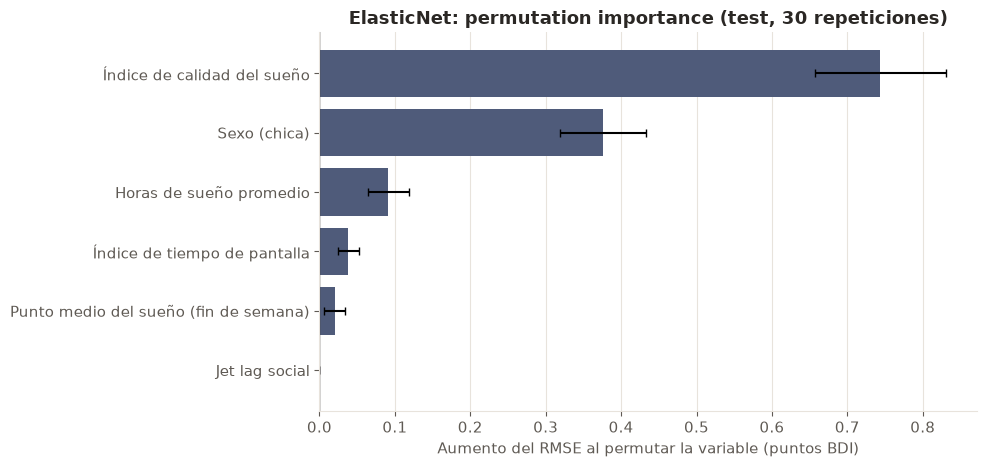

In [25]:
fig = graficar_permutacion(permutacion, "ElasticNet: permutation importance (test, 30 repeticiones)")
plt.show()

La calidad del sueño es, con diferencia, la variable de la que más depende el ElasticNet: desordenarla aumenta el RMSE en 0.74 ± 0.09 puntos. Le sigue el sexo (0.38 ± 0.06) y, a gran distancia, la duración del sueño (0.09 ± 0.03), el tiempo de pantalla (0.04 ± 0.01) y el punto medio del sueño del fin de semana (0.02 ± 0.01). Desordenar el jet lag social no cambia el RMSE en absoluto (0.00 ± 0.00), porque la penalización L1 anuló su coeficiente.

El orden debería coincidir con el de los coeficientes por DE (sección 1) y con el de la media de |SHAP| (sección 3). En un modelo lineal, las tres medidas dependen del coeficiente y de la dispersión de la variable, aunque la permutation importance, al medirse en RMSE, amplifica la distancia entre las variables fuertes y las débiles.

### Guardado

Se guardan en `data/processed/modelado/interpretabilidad/`:

- `importancias.csv`, en formato largo: modelo, método (`coeficiente`, `prediction_values_change`, `loss_function_change`, `shap_global` o `permutacion`), variable, valor y desviación (solo en la permutation importance).
- `casos_explicados.csv`: el `subject_id` de cada adolescente explicado y por qué se eligió.

In [26]:
importancias = tabla_importancias([
    ("elasticnet", "coeficiente", coeficientes["Coeficiente (por DE)"], None),
    ("catboost", "prediction_values_change", importancia_nativa["PredictionValuesChange"], None),
    ("catboost", "loss_function_change", importancia_nativa["LossFunctionChange"], None),
    ("catboost", "shap_global", importancia_shap(shap_clf), None),
    ("elasticnet", "shap_global", importancia_shap(shap_reg), None),
    ("elasticnet", "permutacion", permutacion["Aumento del RMSE (media)"], permutacion["DE"]),
])
guardar_resultados(importancias, {"catboost": casos_clf, "elasticnet": casos_reg})
importancias.pivot_table(index="variable", columns=["modelo", "metodo"], values="valor").round(3)

✓ Guardado en /workspace/data/processed/modelado/interpretabilidad: importancias.csv y casos_explicados.csv


modelo                                            catboost  \
metodo                                loss_function_change   
variable                                                     
Horas de sueño promedio                              0.004   
Jet lag social                                       0.002   
Punto medio del sueño (fin de semana)                0.002   
Sexo (chica)                                         0.015   
Índice de calidad del sueño                          0.039   
Índice de tiempo de pantalla                         0.001   

modelo                                                                      \
metodo                                prediction_values_change shap_global   
variable                                                                     
Horas de sueño promedio                                 14.257       0.191   
Jet lag social                                           9.573       0.052   
Punto medio del sueño (fin de semana)                   10.838       0.105   
Sexo (chica)                                            26.968       0.545   
Índice de calidad del sueño                             30.606       0.410   
Índice de tiempo de pantalla                             7.758       0.088   

modelo                                 elasticnet                          
metodo                                coeficiente permutacion shap_global  
variable                                                                   
Horas de sueño promedio                    -0.905       0.091       0.708  
Jet lag social                              0.000       0.000       0.000  
Punto medio del sueño (fin de semana)       0.408       0.020       0.345  
Sexo (chica)                                3.039       0.376       1.523  
Índice de calidad del sueño                 2.199       0.743       1.675  
Índice de tiempo de pantalla                0.444       0.038       0.374

## 6. Conclusiones

- **¿Es `sleep_quality_index` el predictor dominante en ambos modelos?** Sí. En el ElasticNet es la variable con el mayor efecto por desviación estándar entre las numéricas y la de mayor permutation importance (0.74 puntos de RMSE, el doble que el sexo). En CatBoost encabeza la importancia nativa y la media de |SHAP|: los adolescentes con peor calidad del sueño tienen un riesgo de depresión claramente mayor.
- **¿Qué lugar ocupa `screen_time_index` frente a los dominios del sueño?** Uno secundario. Su efecto tiene el signo esperado (más pantalla, más BDI y más riesgo), pero es pequeño: en el ElasticNet queda por detrás de la calidad y la duración del sueño (0.04 puntos de RMSE frente a 0.74 y 0.09). El tiempo de pantalla aporta poco una vez que se conocen los hábitos de sueño, lo que es coherente con un efecto que actúa en buena parte a través del sueño.
- **¿Qué papel tiene `sex`?** Es el segundo factor en importancia y el de mayor efecto individual: las chicas tienen, con las demás variables fijas, un BDI esperado varios puntos mayor y un riesgo de depresión más alto. Su importancia nativa en CatBoost puede quedar subestimada por ser binaria, por eso conviene leerla en SHAP.
- **¿Coinciden CatBoost y ElasticNet en la jerarquía y la dirección de los efectos?** En lo esencial, sí: los dos ponen primero la calidad del sueño y después el sexo, y coinciden en el signo de los efectos principales (peor calidad del sueño, menos horas de sueño, ser chica y más tiempo de pantalla aumentan el riesgo). Difieren en las variables débiles: el ElasticNet anula el jet lag social, mientras que CatBoost puede repartir la información del cronotipo entre el jet lag social y el punto medio del sueño del fin de semana, que están correlacionados (r = 0.84).